# Notebook 07 — Síntese dos diagnósticos da PUC-Rio (CPC 2023)

**Último notebook da etapa transversal de 2023.** Consolida os resultados já calculados no notebook 06, **sem reajustar modelos** e **sem análise temporal**.

**Referências:** para cada curso da PUC-Rio, os *outros cursos da mesma área e do mesmo grupo* e os *outros cursos da mesma área*. O agrupamento (clustering) C2, K=4 é o principal; C3, K=4 é a análise de robustez.

**Atenção:** os números dos grupos são rótulos arbitrários; não representam classificação de qualidade.


## 1. Configuração e leitura das saídas do notebook 06

Execute primeiro o notebook 06. Este notebook lê seus arquivos CSV exportados, sem modificar os resultados.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = Path.cwd()
ENTRADA = RAIZ / 'resultados_notebook_06' / 'BASE_COMPLETA'
SAIDA = RAIZ / 'resultados_notebook_07' / 'BASE_COMPLETA'
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVOS = {
    'enquadramento': 'diagnostico_enquadramento_PUCRio.csv',
    'comparacoes': 'comparacao_PUC_pares_mesma_area_e_media_area.csv',
    'contribuicoes': 'contribuicoes_distancia_centroide.csv',
}
faltantes = [str(ENTRADA / nome) for nome in ARQUIVOS.values() if not (ENTRADA / nome).exists()]
if faltantes:
    raise FileNotFoundError('Execute o notebook 06 antes. Arquivos ausentes:\n' + '\n'.join(faltantes))
dados = {chave: pd.read_csv(ENTRADA / arquivo, encoding='utf-8-sig')
         for chave, arquivo in ARQUIVOS.items()}
enc = dados['enquadramento']
comp = dados['comparacoes']
contrib = dados['contribuicoes']
C2, C3 = 'C2_8IND', 'C3_4DIM'
INDICADORES = ['Enade_2023','IDD_2023','Mestres_2023','Doutores_2023',
 'Regime_Trabalho_2023','Organizacao_Didatica_2023','Infraestrutura_2023','Oportunidades_2023']
NOMES = {'Enade_2023':'ENADE','IDD_2023':'IDD','Mestres_2023':'Mestres',
 'Doutores_2023':'Doutores','Regime_Trabalho_2023':'Regime de Trabalho',
 'Organizacao_Didatica_2023':'Organização Didática',
 'Infraestrutura_2023':'Infraestrutura','Oportunidades_2023':'Oportunidades'}
assert set(enc.Cenario) >= {C2,C3}
assert set(comp.Cenario) >= {C2,C3}
assert set(contrib.Cenario) >= {C2,C3}
assert set(comp.Indicador) == set(INDICADORES)
assert comp.groupby(['Cenario','Curso_PUC']).size().eq(8).all()
assert enc.groupby('Cenario')['Curso_PUC'].nunique().min() == 8
print('Cursos PUC-Rio:', sorted(enc.Curso_PUC.unique().tolist()))
print('Pasta de saída:', SAIDA)


Cursos PUC-Rio: [23702, 29445, 29446, 32655, 32975, 44431, 59962, 70523]
Pasta de saída: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados_notebook_07\BASE_COMPLETA


## 2. Painel de enquadramento: estabilidade geométrica e posição no grupo

A **silhueta individual** avalia a separação local. O **percentil de distância** indica quão periférico é o curso no grupo global. Não são medidas equivalentes.

In [2]:
painel = enc.pivot(index=['Curso_PUC','Area_2023'], columns='Cenario',
                        values=['Grupo','Silhueta_individual','Percentil_distancia_grupo','N_grupo'])
painel.columns = [f'{m}_{c}' for m,c in painel.columns]
painel = painel.reset_index().sort_values('Curso_PUC')
display(painel.round(3))
painel.to_csv(SAIDA/'07_painel_enquadramento_C2_C3.csv',index=False,encoding='utf-8-sig')


,Curso_PUC,Area_2023,Grupo_C2_8IND,Grupo_C3_4DIM,Silhueta_individual_C2_8IND,Silhueta_individual_C3_4DIM,Percentil_distancia_grupo_C2_8IND,Percentil_distancia_grupo_C3_4DIM,N_grupo_C2_8IND,N_grupo_C3_4DIM
0,23702,5902,1.0,0.0,0.072,0.299,96.568,55.724,437.0,463.0
1,29445,5710,1.0,0.0,0.124,0.327,92.220,36.717,437.0,463.0
2,29446,5806,0.0,0.0,0.024,0.008,69.164,64.147,574.0,463.0
3,32655,5814,2.0,2.0,0.085,0.312,87.889,25.926,611.0,594.0
4,32975,6008,1.0,0.0,0.100,0.054,88.330,61.771,437.0,463.0
5,44431,6208,0.0,0.0,0.029,0.055,94.599,83.153,574.0,463.0
6,59962,21,3.0,1.0,0.008,0.062,88.421,77.119,285.0,354.0
7,70523,6307,2.0,2.0,0.079,0.348,80.524,36.027,611.0,594.0


## 3. Síntese das diferenças por indicador: PUC-Rio menos seus pares

Valores positivos indicam nota da PUC-Rio acima da média dos *outros cursos da mesma área e do mesmo grupo*. Valores negativos indicam o inverso. Não implicam, isoladamente, qualidade ou causalidade.

Indicador,ENADE,IDD,Mestres,Doutores,Regime de Trabalho,Organização Didática,Infraestrutura,Oportunidades
Curso_PUC,,,,,,,,
23702,0.424,0.284,-0.455,0.081,-2.609,1.024,1.619,0.718
29445,-0.001,0.028,-0.346,0.323,-2.497,0.669,1.338,0.867
29446,1.355,0.236,-0.203,1.337,-1.169,-0.946,-0.274,-0.238
32655,0.630,0.048,-0.057,0.609,-1.473,-0.597,1.319,1.470
32975,-0.669,-0.851,-0.595,0.118,-1.981,0.335,1.002,0.649
44431,1.470,-0.158,-0.016,1.000,-2.121,-1.550,-0.373,-0.043
59962,1.289,-0.038,1.490,1.271,-2.600,0.010,0.799,0.619
70523,0.785,0.139,-0.208,0.872,-1.376,-1.134,0.624,0.895


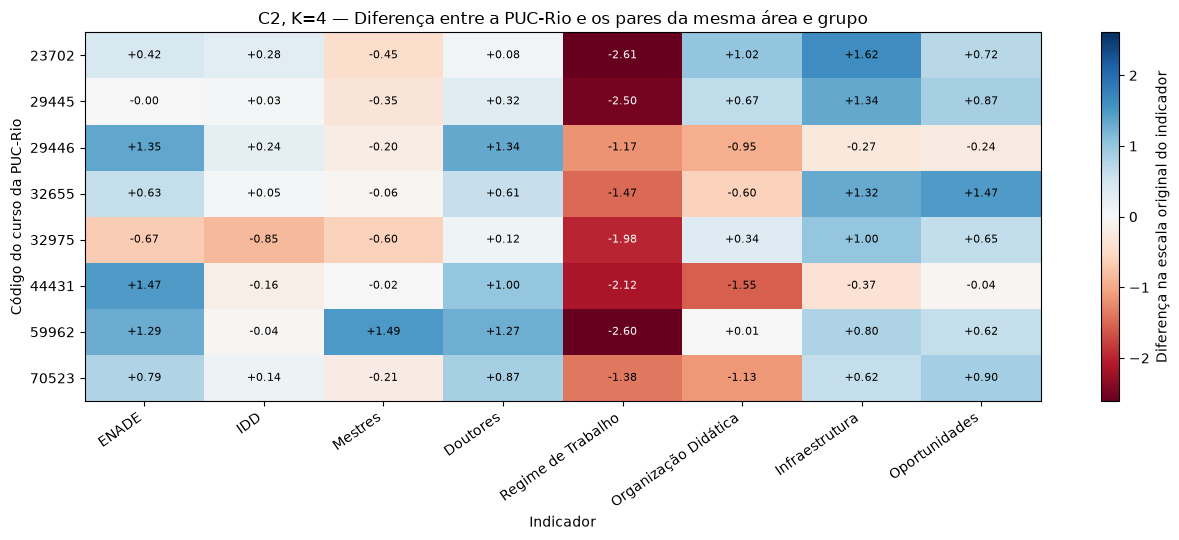

In [3]:
c2 = comp.query('Cenario == @C2').copy()
mat = c2.pivot(index='Curso_PUC',columns='Indicador',values='Diferenca_PUC_menos_pares')
mat = mat.reindex(columns=INDICADORES).sort_index()
display(mat.rename(columns=NOMES).round(3))
mat.to_csv(SAIDA/'07_matriz_diferencas_PUC_menos_pares_C2.csv',encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(13,5.5))
val = mat.to_numpy(float)
lim = max(0.5, np.nanmax(np.abs(val)))
im = ax.imshow(val,aspect='auto',cmap='RdBu',vmin=-lim,vmax=lim)
ax.set_xticks(range(len(INDICADORES)),[NOMES[x] for x in INDICADORES],rotation=35,ha='right')
ax.set_yticks(range(len(mat)),mat.index.astype(str))
ax.set_xlabel('Indicador'); ax.set_ylabel('Código do curso da PUC-Rio')
ax.set_title('C2, K=4 — Diferença entre a PUC-Rio e os pares da mesma área e grupo')
for y in range(len(mat)):
    for x in range(len(INDICADORES)):
        v=val[y,x]
        if np.isfinite(v): ax.text(x,y,f'{v:+.2f}',ha='center',va='center',fontsize=8,
                                    color='white' if abs(v)>lim*.65 else 'black')
fig.colorbar(im,ax=ax,label='Diferença na escala original do indicador')
fig.tight_layout()
fig.savefig(SAIDA/'07_mapa_calor_diferencas_C2.png',dpi=170,bbox_inches='tight')
plt.show()


## 4. Regime de Trabalho: comparação com pares e com a área

O gráfico mostra **diferenças de notas**, não a contribuição para a distância ao centroide. A análise da contribuição aparece na seção seguinte.

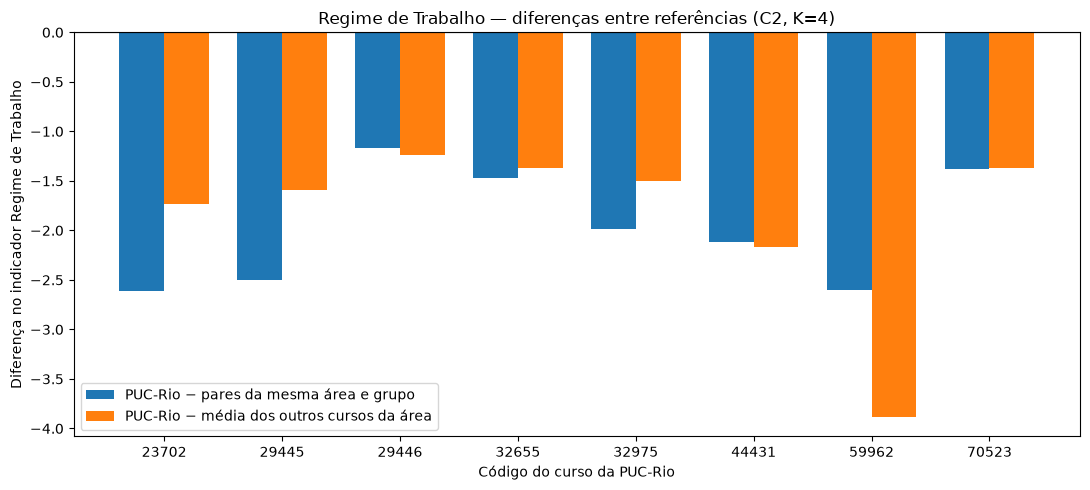

,Curso_PUC,Nota_PUC,Media_mesma_area_e_grupo,Media_area,N_pares_mesma_area_e_grupo
36,23702,2.328,4.937,4.062,61
12,29445,2.464,4.961,4.054,84
20,29446,2.885,4.054,4.125,73
28,32655,2.840,4.313,4.213,39
44,32975,2.969,4.950,4.465,24
52,44431,1.903,4.024,4.068,110
4,59962,0.000,2.600,3.887,54
60,70523,3.070,4.446,4.435,36


In [4]:
reg = c2.loc[c2.Indicador.eq('Regime_Trabalho_2023')].sort_values('Curso_PUC')
x = np.arange(len(reg))
fig,ax=plt.subplots(figsize=(11,5))
ax.bar(x-.19,reg['Nota_PUC']-reg['Media_mesma_area_e_grupo'],width=.38,
       label='PUC-Rio − pares da mesma área e grupo')
ax.bar(x+.19,reg['Nota_PUC']-reg['Media_area'],width=.38,
       label='PUC-Rio − média dos outros cursos da área')
ax.axhline(0,color='black',lw=.8)
ax.set_xticks(x,reg.Curso_PUC.astype(str))
ax.set_ylabel('Diferença no indicador Regime de Trabalho')
ax.set_xlabel('Código do curso da PUC-Rio')
ax.set_title('Regime de Trabalho — diferenças entre referências (C2, K=4)')
ax.legend()
fig.tight_layout()
fig.savefig(SAIDA/'07_regime_trabalho_diferencas.png',dpi=170,bbox_inches='tight')
plt.show()
display(reg[['Curso_PUC','Nota_PUC','Media_mesma_area_e_grupo','Media_area',
             'N_pares_mesma_area_e_grupo']].round(3))


## 5. Quais indicadores explicam a distância ao centroide global?

A contribuição é calculada no espaço **padronizado de oito dimensões do C2** e soma 100% por curso. É diferente da comparação com pares da mesma área.

Indicador_ou_dimensao,ENADE,IDD,Mestres,Doutores,Regime de Trabalho,Organização Didática,Infraestrutura,Oportunidades
Curso_PUC,,,,,,,,
23702,2.3,0.3,1.4,0.1,53.0,5.6,27.3,10.0
29445,0.4,0.6,1.8,0.1,61.2,6.2,22.1,7.6
29446,30.9,1.2,1.5,25.5,18.8,17.9,2.5,1.7
32655,11.3,0.0,0.2,3.0,21.4,10.5,24.5,29.2
32975,8.7,17.2,4.8,2.2,45.0,0.1,15.3,6.6
44431,31.7,0.3,0.0,7.1,36.0,23.8,1.1,0.0
59962,21.7,0.3,17.3,7.4,42.1,0.2,5.3,5.8
70523,17.3,0.0,0.1,22.2,18.4,13.3,7.2,21.4


,Curso_PUC,Indicador,Contribuicao_pct
4,23702,Regime de Trabalho,53.03
6,23702,Infraestrutura,27.27
7,23702,Oportunidades,10.04
12,29445,Regime de Trabalho,61.23
14,29445,Infraestrutura,22.09
15,29445,Oportunidades,7.62
16,29446,ENADE,30.87
19,29446,Doutores,25.48
20,29446,Regime de Trabalho,18.81
31,32655,Oportunidades,29.21


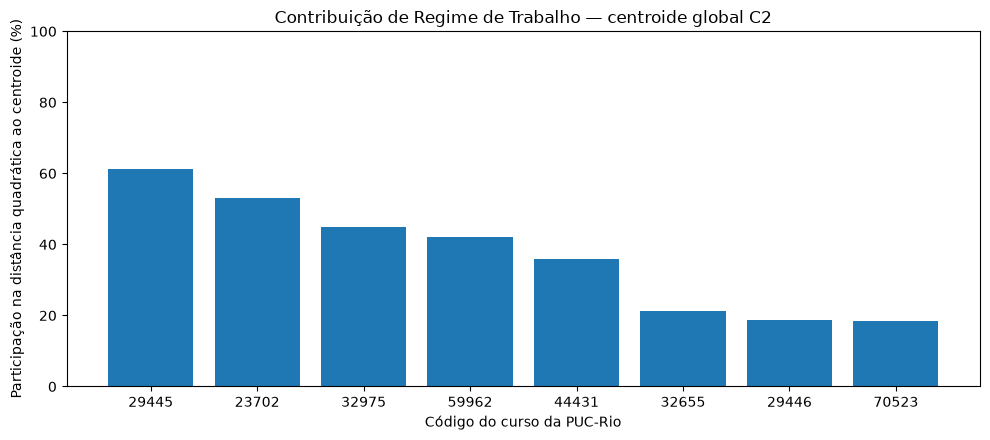

In [5]:
cc2 = contrib.query('Cenario == @C2').copy()
part = cc2.pivot(index='Curso_PUC',columns='Indicador_ou_dimensao',
                 values='Contribuicao_percentual').reindex(columns=INDICADORES).sort_index()
assert np.allclose(part.sum(axis=1),100,atol=1e-5)
display(part.rename(columns=NOMES).round(1))
top = (part.stack().rename('Contribuicao_pct').reset_index()
       .rename(columns={'Indicador_ou_dimensao':'Indicador'}))
top['Indicador'] = top['Indicador'].map(NOMES)
top = top.sort_values(['Curso_PUC','Contribuicao_pct'],ascending=[True,False])
display(top.groupby('Curso_PUC').head(3).round(2))
top.groupby('Curso_PUC').head(3).to_csv(SAIDA/'07_top3_contribuicoes_centroide.csv',
                                      index=False,encoding='utf-8-sig')
reg_pct = part['Regime_Trabalho_2023'].sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(10,4.5))
ax.bar(reg_pct.index.astype(str),reg_pct.values)
ax.set_ylim(0,100)
ax.set_ylabel('Participação na distância quadrática ao centroide (%)')
ax.set_xlabel('Código do curso da PUC-Rio')
ax.set_title('Contribuição de Regime de Trabalho — centroide global C2')
fig.tight_layout()
fig.savefig(SAIDA/'07_regime_contribuicao_centroide.png',dpi=170,bbox_inches='tight')
plt.show()


## 6. Os cursos da PUC-Rio são centrais ou periféricos?

Um curso pode estar **estavelmente classificado**, mas ser **periférico**. A silhueta baixa também sugere cautela na interpretação da associação ao grupo.

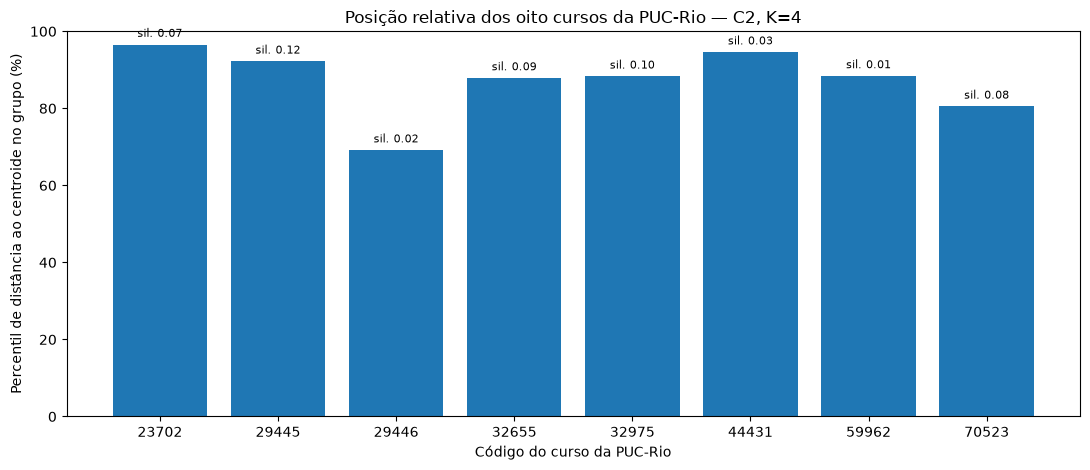

In [6]:
puc_c2 = enc.query('Cenario == @C2').sort_values('Curso_PUC')
fig,ax=plt.subplots(figsize=(11,4.8))
ax.bar(puc_c2.Curso_PUC.astype(str),puc_c2.Percentil_distancia_grupo)
ax.set_ylim(0,100)
ax.set_ylabel('Percentil de distância ao centroide no grupo (%)')
ax.set_xlabel('Código do curso da PUC-Rio')
ax.set_title('Posição relativa dos oito cursos da PUC-Rio — C2, K=4')
for i,(_,r) in enumerate(puc_c2.iterrows()):
    ax.text(i,min(r.Percentil_distancia_grupo+2,99),
            f'sil. {r.Silhueta_individual:.2f}',ha='center',fontsize=8)
fig.tight_layout()
fig.savefig(SAIDA/'07_percentis_silhuetas_C2.png',dpi=170,bbox_inches='tight')
plt.show()


## 7. Robustez: as conclusões mudam no C3?

Comparamos **diferenças em relação aos pares da mesma área e do mesmo grupo em cada cenário**, sem supor que os rótulos dos grupos C2 e C3 sejam equivalentes. A comparação é descritiva.

,Curso_PUC,Indicadores_mesmo_sinal,Mudanca_media_absoluta
0,23702,8,0.042
1,29445,7,0.046
2,29446,3,1.073
3,32655,8,0.081
4,32975,8,0.055
5,44431,4,1.138
6,59962,6,0.086
7,70523,8,0.094


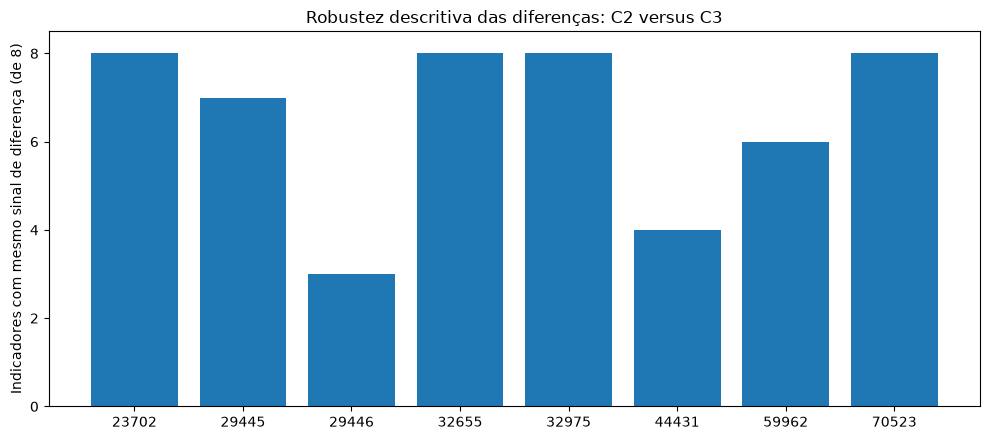

In [7]:
difs = comp.pivot(index=['Curso_PUC','Indicador'],columns='Cenario',
                  values='Diferenca_PUC_menos_pares').reset_index()
difs['Sinal_C2'] = np.sign(difs[C2])
difs['Sinal_C3'] = np.sign(difs[C3])
difs['Mesmo_sinal'] = difs['Sinal_C2'].eq(difs['Sinal_C3'])
difs['Mudanca_absoluta'] = (difs[C2]-difs[C3]).abs()
resumo_rob = difs.groupby('Curso_PUC').agg(
    Indicadores_mesmo_sinal=('Mesmo_sinal','sum'),
    Mudanca_media_absoluta=('Mudanca_absoluta','mean')).reset_index()
display(resumo_rob.round(3))
difs.to_csv(SAIDA/'07_comparacao_diferencas_C2_C3.csv',index=False,encoding='utf-8-sig')
resumo_rob.to_csv(SAIDA/'07_resumo_robustez_C2_C3.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(10,4.5))
ax.bar(resumo_rob.Curso_PUC.astype(str),resumo_rob.Indicadores_mesmo_sinal)
ax.set_ylim(0,8.5)
ax.set_yticks(range(0,9,2))
ax.set_ylabel('Indicadores com mesmo sinal de diferença (de 8)')
ax.set_title('Robustez descritiva das diferenças: C2 versus C3')
fig.tight_layout()
fig.savefig(SAIDA/'07_robustez_sinais_C2_C3.png',dpi=170,bbox_inches='tight')
plt.show()


## 8. Tabela final por curso: diagnóstico resumido e verificável

A tabela destaca a maior diferença **em valor absoluto** em relação aos pares e o indicador com maior contribuição para a distância ao centroide. Não trata uma diferença negativa como deficiência.

In [8]:
linhas=[]
for _,r in puc_c2.iterrows():
    curso = int(r.Curso_PUC)
    sub = c2.loc[c2.Curso_PUC.eq(curso)].copy()
    maior = sub.loc[sub.Diferenca_PUC_menos_pares.abs().idxmax()]
    p = part.loc[curso]
    principal = p.idxmax()
    linhas.append({
        'Curso_PUC':curso,'Area_2023':r.Area_2023,'Grupo_C2':int(r.Grupo),
        'N_pares_mesma_area_e_grupo':int(sub.N_pares_mesma_area_e_grupo.iloc[0]),
        'Silhueta_individual_C2':r.Silhueta_individual,
        'Percentil_distancia_C2':r.Percentil_distancia_grupo,
        'Maior_diferenca_vs_pares':NOMES[maior.Indicador],
        'Valor_diferenca_vs_pares':maior.Diferenca_PUC_menos_pares,
        'Principal_contribuicao_centroide':NOMES[principal],
        'Contribuicao_principal_pct':p.max(),
        'Contribuicao_regime_pct':p['Regime_Trabalho_2023'],
        'Indicadores_mesmo_sinal_C2_C3':int(resumo_rob.set_index('Curso_PUC').loc[curso,'Indicadores_mesmo_sinal'])
    })
sintese = pd.DataFrame(linhas).sort_values('Curso_PUC')
display(sintese.round(3))
sintese.to_csv(SAIDA/'07_sintese_oito_cursos_PUCRio.csv',index=False,encoding='utf-8-sig')


,Curso_PUC,Area_2023,Grupo_C2,N_pares_mesma_area_e_grupo,Silhueta_individual_C2,Percentil_distancia_C2,Maior_diferenca_vs_pares,Valor_diferenca_vs_pares,Principal_contribuicao_centroide,Contribuicao_principal_pct,Contribuicao_regime_pct,Indicadores_mesmo_sinal_C2_C3
0,23702,5902,1,61,0.072,96.568,Regime de Trabalho,-2.609,Regime de Trabalho,53.026,53.026,8
1,29445,5710,1,84,0.124,92.220,Regime de Trabalho,-2.497,Regime de Trabalho,61.227,61.227,7
2,29446,5806,0,73,0.024,69.164,ENADE,1.355,ENADE,30.870,18.808,3
3,32655,5814,2,39,0.085,87.889,Regime de Trabalho,-1.473,Oportunidades,29.209,21.362,8
4,32975,6008,1,24,0.100,88.330,Regime de Trabalho,-1.981,Regime de Trabalho,45.022,45.022,8
5,44431,6208,0,110,0.029,94.599,Regime de Trabalho,-2.121,Regime de Trabalho,35.960,35.960,4
6,59962,21,3,54,0.008,88.421,Regime de Trabalho,-2.600,Regime de Trabalho,42.098,42.098,6
7,70523,6307,2,36,0.079,80.524,Regime de Trabalho,-1.376,Doutores,22.165,18.403,8


## 9. Checagens e conclusões metodológicas

- **C2, K=4** é a referência principal; **C3, K=4** serve para avaliar sensibilidade.
- O grupo foi calculado na base completa. Os **pares do gráfico** são apenas cursos da **mesma área e grupo**, excluindo o curso da PUC-Rio.
- A média da área também exclui o próprio curso.
- A contribuição para a distância ao centroide refere-se ao **grupo global**, não à média dos pares da área.
- O sinal da diferença não estabelece causalidade ou qualidade institucional.
- A silhueta individual e a distância ao centroide devem acompanhar a interpretação dos grupos.
- A análise é **transversal de 2023**; nenhuma inferência temporal é feita.

**Produto final:** tabelas e figuras na pasta `resultados_notebook_07/BASE_COMPLETA`, prontas para apoiar a redação dos resultados.